# ⚔️ CHESS AI ARENA: ALPHAZERO (MCTS) vs DEEP Q-NETWORK (DQN)

Welcome to the **Professional Chess AI Arena**, an experimental and visualization platform showcasing the ultimate showdown between the two most prominent Reinforcement Learning (RL) paradigms of today, running directly on Google Colab.

This notebook is designed to be fully self-contained, integrating and restoring two actual deep neural network architectures from your project codebase, and directly mounting your Google Drive to load pre-trained weights.

---

## 📂 Google Drive Connection & Checkpoint Paths

To ensure maximum convenience and avoid having to re-upload your models every time Google Colab disconnects, this notebook is programmed to connect directly with your **Google Drive** and load stored checkpoints.

The system will automatically look for weights at:
*   AlphaZero weights: `/content/drive/MyDrive/alphaOne/v1_finetuned_ep5.pth`
*   DQN weights: `/content/drive/MyDrive/alphaOne/dqn_best.pth`

---

## 📚 1. THEORETICAL FOUNDATIONS & ARCHITECTURE: ALPHAZERO vs DQN

Below is an in-depth mathematical analysis of the state representation, reward signals, action-value estimations, and learning algorithms utilized by both paradigms.

---

### ♟️ A. STATE REPRESENTATION

To enable deep convolutional neural networks (CNN/ResNet) to interpret a chess board, the physical board state $s$ is encoded into a **3D feature tensor** of size $(18, 8, 8)$ (often visualized as a multi-layered board state):

*   **8x8 Spatial Grid:** Represents the 64 squares from rank `1-8` and files `a-h`.
*   **18 Information Channels (Planes):**
    *   **Channels 0 - 5:** White piece positions (Pawn, Knight, Bishop, Rook, Queen, King). The occupied squares are set to `1.0`, while others are `0.0`.
    *   **Channels 6 - 11:** Black piece positions.
    *   **Channel 12:** Current turn (filled with `1.0` if White's turn, `0.0` if Black's turn).
    *   **Channels 13 - 16:** Castling rights (Kingside/Queenside for White, Kingside/Queenside for Black - filled with `1.0` if still valid).
    *   **Channel 17:** Active en-passant target square (filled with `1.0` if an en-passant capture is possible).

---

### 🏆 B. REWARD FUNCTION

The formulation of the reward $R(s, a)$ when transitioning from state $s$ to $s'$ via action $a$ reflects the fundamentally different learning philosophies of the two models:

#### 1. Deep Q-Network (DQN) — Dense Rewards
DQN employs a dense reward structure distributed at every move to quickly guide the AI's search:
*   **Checkmate:** $+10.0$ (Absolute win)
*   **Draw Penalty:** $-0.2$ (Small penalty to discourage passive play or early draws)
*   **Material Balance ($\Delta$ Material):**
    $$R_{\text{material}} = \text{Material Balance}_{\text{after}} - \text{Material Balance}_{\text{before}}$$
    With standard piece values: Pawn = 1.0, Knight = 3.0, Bishop = 3.0, Rook = 5.0, Queen = 9.0, King = 0.0.
*   **Step Penalty:** $-0.01$ per move to encourage the AI to find checkmates as fast as possible.

Total DQN Reward Formulation:
$$\text{Reward}_{\text{DQN}} = \Delta \text{Material} - 0.01 \quad (\text{or } +10.0 \, / \, -0.2 \text{ upon game termination})$$

#### 2. AlphaZero — Sparse Rewards
Pure AlphaZero only receives a reward signal at the **end of the game** ($z$):
*   **Win:** $+1.0$
*   **Loss:** $-1.0$
*   **Draw:** $-0.9$ (Draw = Loss strategy to aggressively prevent passive drawing tendencies in chess)

> 💡 **Note:** During search, the **Value Head ($v$)** of the neural network acts as a **learned dense surrogate evaluation function**, predicting the final outcome $z$ from non-terminal states to guide the MCTS tree search.

---

### 📊 C. Q-VALUES AND ACTION SELECTION

The Q-value represents the quality score of taking action $a$ in state $s$: $Q(s, a)$.

#### 1. DQN Model — Function Approximation via Neural Network
DQN **does not use a physical Q-table** since storing $10^{120}$ chess positions is memory-impossible. Instead, a deep convolutional neural network (6 ResBlocks, 128 channels) acts as a function approximator:

$$\text{Input: } s \text{ (18, 8, 8)} \longrightarrow \text{ChessDQN} \longrightarrow \text{Output: Q-vector } \mathbf{q} \in \mathbb{R}^{4272}$$

Each element in the output vector directly represents the estimated $Q(s, a)$ value of that move. The AI moves by choosing the legal move with the highest Q-value:
$$a^* = \arg\max_{a \in \text{Legals}} Q(s, a)$$

#### 2. AlphaZero Model — Dynamic Search Tree Values
AlphaZero **maintains localized Q-values dynamically** within the nodes of the MCTS search tree. Each edge connecting state $s$ to action $a$ stores:
*   $N(s, a)$: Visit count
*   $W(s, a)$: Total action value accumulated from leaf node backpropagations
*   $Q(s, a)$: Mean action-value of the edge, calculated as:
    $$Q(s, a) = \frac{W(s, a)}{N(s, a)}$$

This $Q(s, a)$ is combined with the network's prior probability $P(s, a)$ (from the Policy Head) to guide the **PUCT** selection formula:
$$a^* = \arg\max_{a} \left( Q(s, a) + C_{\text{puct}} \cdot P(s, a) \cdot \frac{\sqrt{N(s)}}{1 + N(s, a)} \right)$$

---

### 🧠 D. LEARNING MECHANISMS AND MATHEMATICAL FORMULAS

#### 1. DQN Learning Algorithm: Temporal Difference (TD) Learning

DQN learns by minimizing the TD error between the current prediction and target values using a **Target Network** ($\theta^-$) and an **Experience Replay Buffer** ($\mathcal{D}$).

##### 🎯 Training Target (Negamax TD target)
Since chess is a two-player zero-sum game, the opponent's best response in the next state is our disadvantage:

$$Y^{\text{DQN}} = r - \gamma \max_{a' \in \text{Legals}(s')} Q(s', a'; \theta^-) \times (1 - \text{done})$$

##### 📉 Loss Function
Uses Huber Loss (smooth L1 loss) to prevent gradient explosion and optimize weights $\theta$:

$$\mathcal{L}(\theta) = \mathbb{E}_{(s, a, r, s', d) \sim \mathcal{D}} \left[ \text{Huber}\left( Y^{\text{DQN}} - Q(s, a; \theta) \right) \right]$$

---

#### 2. AlphaZero Learning Algorithm: MCTS-Guided Self-Play RL

AlphaZero trains the neural network to predict values that match both the deep MCTS search distributions and the actual game outcomes.

##### 🪵 MCTS as a Policy Improvement Operator
At each state $s$, MCTS simulations yield a search probability distribution $\pi$ based on visit counts:

$$\pi_a = \frac{N(s, a)^{1/\tau}}{\sum_b N(s, b)^{1/\tau}}$$

##### ⚔️ Combined Dual-Head Loss Function
The neural network $\theta$ is jointly optimized on both Policy ($\mathbf{p}$) and Value ($v$) predictions:

$$\mathcal{L}(\theta) = (z - v)^2 - \pi^{\top} \log \mathbf{p} + c \|\theta\|^2$$

---

## 📊 E. COMPREHENSIVE COMPARISON OF THE TWO PARADIGMS

| Feature | 🔴 ALPHAZERO (MCTS) | ⚫ CHESSDQN |
| :--- | :--- | :--- |
| **Theoretical Nature** | Model-Based Planning & Self-Play RL | Model-Free Temporal Difference (TD) |
| **Q-value Representation** | Local and dynamic on MCTS edges | Continuous estimation via CNN output vector |
| **Reward Signal** | Sparse: `+1.0 / -1.0 / -0.9` at game end | Dense: Relative material balance on each move |
| **Target Formulation** | Matches MCTS distribution and final outcome | Negamax TD target: `r - gamma * max Q(s', a')` |
| **Loss Function** | Joint Loss: MSE (Value) + Cross-Entropy (Policy) | Huber Loss / MSE on TD error |
| **ResNet Architecture** | **10 Blocks** (Channels: 192) | **6 Blocks** (Channels: 128) |
| **Move Generation Speed** | Slower (deep, structured search) | Instantaneous (direct neural network feedforward) |

## 1. Install Dependencies
We install `python-chess` for rules and visual SVG rendering in Google Colab.


In [ ]:
!pip install python-chess --quiet

## 2. Core Imports, Device & Google Drive Setup


In [ ]:
import os
import math
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import chess
from IPython.display import display, HTML, clear_output

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"Device in use: {device}")

# Mount Google Drive for persistent weights access
from google.colab import drive
drive.mount('/content/drive')



CUDA Available: False
Device in use: cpu
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. State & Action Encoder
Converts the chess board state into an `(18, 8, 8)` tensor and maps moves to indices `[0-4271]`.


In [ ]:
# Generate Action Space
FILES = "abcdefgh"
RANKS = "12345678"
PROMOTIONS = ['q', 'r', 'n', 'b']
ALL_UCI_MOVES = []

for f1 in FILES:
    for r1 in RANKS:
        for f2 in FILES:
            for r2 in RANKS:
                ALL_UCI_MOVES.append(f"{f1}{r1}{f2}{r2}")

for f1 in FILES:
    for f2 in FILES:
        if abs(FILES.index(f1) - FILES.index(f2)) <= 1:
            for p in PROMOTIONS:
                ALL_UCI_MOVES.append(f"{f1}7{f2}8{p}")
                ALL_UCI_MOVES.append(f"{f1}2{f2}1{p}")

ALL_UCI_MOVES = sorted(list(set(ALL_UCI_MOVES)))
MOVE_TO_INDEX = {move: i for i, move in enumerate(ALL_UCI_MOVES)}
INDEX_TO_MOVE = {i: move for move, i in MOVE_TO_INDEX.items()}

class Encoder:
    @staticmethod
    def board_to_tensor(board: chess.Board) -> torch.Tensor:
        """Converts chess board into an (18, 8, 8) tensor."""
        tensor = np.zeros((18, 8, 8), dtype=np.float32)

        # 1. Piece positions
        for square in chess.SQUARES:
            piece = board.piece_at(square)
            if piece:
                color = 1 if piece.color == chess.WHITE else 0
                piece_type = piece.piece_type - 1 # 0 to 5
                channel = piece_type if color == 1 else piece_type + 6
                rank, file = chess.square_rank(square), chess.square_file(square)
                tensor[channel, rank, file] = 1.0

        # 2. Whose turn is it
        if board.turn == chess.WHITE:
            tensor[12, :, :] = 1.0

        # 3. Castling rights
        if board.has_kingside_castling_rights(chess.WHITE): tensor[13, :, :] = 1.0
        if board.has_queenside_castling_rights(chess.WHITE): tensor[14, :, :] = 1.0
        if board.has_kingside_castling_rights(chess.BLACK): tensor[15, :, :] = 1.0
        if board.has_queenside_castling_rights(chess.BLACK): tensor[16, :, :] = 1.0

        # 4. En-passant square
        if board.ep_square is not None:
            rank, file = chess.square_rank(board.ep_square), chess.square_file(board.ep_square)
            tensor[17, rank, file] = 1.0

        return torch.tensor(tensor)



## 4. AlphaZero Architecture (10 Blocks, 192 Channels)
This is your exact AlphaZeroNetV1 architecture matching `best_model.pth`.


In [ ]:
class ResBlockV1(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(channels)

    def forward(self, x):
        residual = x
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + residual
        return F.relu(out)

class AlphaZeroNetV1(nn.Module):
    def __init__(self, num_blocks: int = 10, num_channels: int = 192,
                 num_input_channels: int = 18, num_moves: int = 4272):
        super().__init__()

        self.initial_conv = nn.Sequential(
            nn.Conv2d(num_input_channels, num_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(num_channels),
            nn.ReLU(inplace=True)
        )

        self.res_blocks = nn.ModuleList([
            ResBlockV1(num_channels) for _ in range(num_blocks)
        ])

        # Policy Head
        self.policy_conv = nn.Conv2d(num_channels, 2, kernel_size=1, bias=False)
        self.policy_bn   = nn.BatchNorm2d(2)
        self.policy_fc   = nn.Linear(2 * 8 * 8, num_moves)

        # Value Head
        self.value_conv  = nn.Conv2d(num_channels, 1, kernel_size=1, bias=False)
        self.value_bn    = nn.BatchNorm2d(1)
        self.value_fc1   = nn.Linear(1 * 8 * 8, 256)
        self.value_fc2   = nn.Linear(256, 1)

    def forward(self, x: torch.Tensor):
        x = self.initial_conv(x)
        for block in self.res_blocks:
            x = block(x)

        # Policy
        p = F.relu(self.policy_bn(self.policy_conv(x)))
        p = p.reshape(p.size(0), -1)
        policy_logits = self.policy_fc(p)

        # Value
        v = F.relu(self.value_bn(self.value_conv(x)))
        v = v.reshape(v.size(0), -1)
        v = F.relu(self.value_fc1(v))
        value = torch.tanh(self.value_fc2(v))

        return policy_logits, value

## 5. Chess DQN Architecture (6 Blocks, 128 Channels)
This is your exact ChessDQN architecture matching `dqn_model.pth`.


In [ ]:
class ResBlockDQN(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(channels)

    def forward(self, x):
        residual = x
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + residual
        return F.relu(out)

class ChessDQN(nn.Module):
    def __init__(self, num_blocks: int = 6, num_channels: int = 128,
                 num_input_channels: int = 18, num_moves: int = 4272):
        super().__init__()

        self.initial_conv = nn.Sequential(
            nn.Conv2d(num_input_channels, num_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(num_channels),
            nn.ReLU(inplace=True)
        )

        self.res_blocks = nn.ModuleList([
            ResBlockDQN(num_channels) for _ in range(num_blocks)
        ])

        # Q FC Head
        self.q_conv = nn.Conv2d(num_channels, 4, kernel_size=1, bias=False)
        self.q_bn   = nn.BatchNorm2d(4)

        policy_flat = 4 * 8 * 8
        self.q_fc1  = nn.Linear(policy_flat, 256)
        self.q_fc2  = nn.Linear(256, num_moves)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.initial_conv(x)
        for block in self.res_blocks:
            x = block(x)

        x_q = F.relu(self.q_bn(self.q_conv(x)))
        x_q = x_q.reshape(x_q.size(0), -1)
        x_q = F.relu(self.q_fc1(x_q))
        q_values = self.q_fc2(x_q)

        return q_values

    def select_action(self, state_tensor: torch.Tensor, legal_moves: list) -> tuple:
        """Selects action via masked Q-value calculation."""
        with torch.no_grad():
            q_values = self.forward(state_tensor)[0].cpu().numpy()

        masked_q = np.full(4272, -1e9, dtype=np.float32)
        for move in legal_moves:
            idx = MOVE_TO_INDEX.get(move.uci())
            if idx is not None:
                masked_q[idx] = q_values[idx]

        best_move_idx = np.argmax(masked_q)
        best_move_uci = INDEX_TO_MOVE[best_move_idx]
        return chess.Move.from_uci(best_move_uci), q_values[best_move_idx]



## 6. Weight Loading Utility


In [ ]:
def load_model_weights(model: nn.Module, filepath: str, model_name: str):
    """Loads state dict if the file exists, with smart nested key extraction."""
    if os.path.exists(filepath):
        try:
            checkpoint = torch.load(filepath, map_location=device)

            # Support both direct state dict and wrapped checkpoint dictionaries
            state_dict = None
            for key in ["model_state_dict", "state_dict"]:
                if isinstance(checkpoint, dict) and key in checkpoint:
                    state_dict = checkpoint[key]
                    break

            if state_dict is None:
                state_dict = checkpoint # Assume direct state_dict

            model.load_state_dict(state_dict)
            print(f"✅ Successfully loaded pre-trained weights for {model_name} from: '{filepath}'")
        except Exception as e:
            print(f"⚠️ Error loading weights for {model_name}: {e}. Initializing randomly.")
    else:
        print(f"⚠️ File '{filepath}' not found. {model_name} initialized with RANDOM weights.")



## 7. MCTS Node & AlphaZero Tree Search Guidance


In [ ]:
class MCTSNode:
    def __init__(self, prior=0.0):
        self.P = prior
        self.N = 0
        self.W = 0.0
        self.Q = 0.0
        self.children = {}

    def expand(self, legal_moves, action_probs, board=None):
        for move in legal_moves:
            idx = MOVE_TO_INDEX.get(move.uci(), 0)
            p = action_probs[idx]

            # Mate-in-1 priority check
            if board is not None:
                board.push(move)
                if board.is_checkmate():
                    p += 15.0
                board.pop()

            self.children[move] = MCTSNode(prior=p)

    def is_leaf(self):
        return len(self.children) == 0

    def select_child(self, c_puct=1.5):
        best_uct = -float('inf')
        best_child = None
        best_action = None
        sum_N = math.sqrt(self.N + 1)

        for action, child in self.children.items():
            u = c_puct * child.P * sum_N / (1 + child.N)
            uct = child.Q + u
            if uct > best_uct:
                best_uct = uct
                best_child = child
                best_action = action
        return best_action, best_child

    def backprop(self, value):
        self.N += 1
        self.W += value
        self.Q = self.W / self.N

def run_mcts_search(board: chess.Board, model: nn.Module, num_simulations=50) -> tuple:
    """Executes Monte Carlo Tree Search guided by AlphaZero policy/value outputs."""
    root = MCTSNode()

    # 1. Root Evaluation
    state_tensor = Encoder.board_to_tensor(board).unsqueeze(0).to(device)
    with torch.no_grad():
        logits, _ = model(state_tensor)
        probs = F.softmax(logits, dim=1)[0].cpu().numpy()

    root.expand(list(board.legal_moves), probs, board)

    # 2. Iterative Simulations
    for _ in range(num_simulations):
        sim_board = board.copy()
        node = root
        path = [node]

        # Selection
        while not node.is_leaf():
            action, child = node.select_child()
            path.append(child)
            sim_board.push(action)
            node = child

        # Evaluation & Expansion
        if sim_board.is_game_over():
            res = sim_board.result()
            # Draw punishment
            v = -0.9 if res == '1/2-1/2' else -1.0
        else:
            s_t = Encoder.board_to_tensor(sim_board).unsqueeze(0).to(device)
            with torch.no_grad():
                logits, value = model(s_t)
                probs = F.softmax(logits, dim=1)[0].cpu().numpy()
                v = value.item()
            node.expand(list(sim_board.legal_moves), probs, sim_board)

        # Backpropagation
        for n in reversed(path):
            v = -v
            n.backprop(v)

    # Selected action: Most visited node
    best_move = max(root.children.items(), key=lambda item: item[1].N)[0]
    return best_move, root



## 8. Initialize Models & Load Weights from Drive


In [ ]:
# 1. Instantiate the correct models
dqn_net = ChessDQN(num_blocks=6, num_channels=128).to(device)
az_net = AlphaZeroNetV1(num_blocks=10, num_channels=192).to(device)

dqn_net.eval()
az_net.eval()

print("Initializing structures... Please wait.")
time.sleep(1)

# 2. Load weights directly from mounted Google Drive
load_model_weights(az_net, "/content/drive/MyDrive/alphaOne/v1_finetuned_ep5.pth", "AlphaZero (MCTS)")
load_model_weights(dqn_net, "/content/drive/MyDrive/alphaOne/dqn_best.pth", "ChessDQN")



Initializing structures... Please wait.
✅ Successfully loaded pre-trained weights for AlphaZero (MCTS) from: '/content/drive/MyDrive/alphaOne/v1_finetuned_ep5.pth'
✅ Successfully loaded pre-trained weights for ChessDQN from: '/content/drive/MyDrive/alphaOne/dqn_best.pth'


## 9. Automated Chess AI Battle Arena Loop
Runs the match in real time, visualizing the SVG board dynamically inside Google Colab.
You can customize who plays White ("mcts", "dqn", "random") and Black.


In [ ]:
def play_ai_battle(white_type="mcts", black_type="dqn", mcts_simulations=50, max_moves=100):
    """
    Simulates a head-to-head match between two chess AIs with real-time Colab rendering.
    Args:
        white_type: "mcts" (AlphaZero), "dqn", or "random"
        black_type: "mcts" (AlphaZero), "dqn", or "random"
        mcts_simulations: number of simulation rollouts per move
        max_moves: cap the match to prevent endless draws
    """
    board = chess.Board()
    move_count = 0

    print("🎬 Initializing Chess Arena... Round starts in 2 seconds.")
    time.sleep(2)

    while not board.is_game_over() and move_count < max_moves:
        turn = board.turn
        player_name = "🔴 WHITE" if turn == chess.WHITE else "⚫ BLACK"
        agent_type = white_type if turn == chess.WHITE else black_type

        start_time = time.time()
        info = ""

        # 1. Agent selects move
        if agent_type == "mcts":
            move, root = run_mcts_search(board, az_net, num_simulations=mcts_simulations)
            info = f"AlphaZero MCTS (Sims: {mcts_simulations}, Root Visits: {root.N}, Eval Q: {root.Q:.4f})"
        elif agent_type == "dqn":
            state_tensor = Encoder.board_to_tensor(board).unsqueeze(0).to(device)
            move, q_val = dqn_net.select_action(state_tensor, list(board.legal_moves))
            info = f"ChessDQN (Estimated Q-value: {q_val:.4f})"
        else:
            move = random.choice(list(board.legal_moves))
            info = "Random Move (No model guidance)"

        elapsed = time.time() - start_time

        # 2. Push move to board state
        board.push(move)
        move_count += 1

        # 3. Dynamic graphic updates
        clear_output(wait=True)
        print("==========================================================================")
        print(f" ⚔️ CHESS AI ARENA | MOVE #{move_count} | PLAYER: {player_name}")
        print(f"  Current Algorithm: {agent_type.upper()}")
        print(f"  Decision Details : {info}")
        print(f"  Selected Action  : {move.uci()} (Calculated in {elapsed:.2f} seconds)")
        print("==========================================================================")

        # Render board SVG in Colab
        display(board)

        if board.is_check():
            print("🚨 CHECK!")

        # Pause slightly to allow user to view the board state updates
        time.sleep(1.2)

    # Match conclusion
    clear_output(wait=True)
    print("========================= MATCH OVER =========================")
    if board.is_game_over():
        print(f"🏆 Final Result: {board.result()}")
        if board.is_checkmate():
            winner = "BLACK (Đen)" if board.turn == chess.WHITE else "WHITE (Trắng)"
            print(f"🎉 Checkmate! Winner: {winner}")
        elif board.is_stalemate() or board.is_insufficient_material() or board.is_seventyfive_moves() or board.is_fivefold_repetition():
            print("🤝 Draw by Chess Rules!")
    else:
        print(f"🛑 Match stopped by exceeding the move limit ({max_moves} moves).")

    display(board)



## 10. Start the Battle!
Run this cell to start the real-time face-off between your pre-trained models.
You can play with:
- `white_type="mcts"` (AlphaZeroNetV1)
- `black_type="dqn"` (ChessDQN)


========================= MATCH OVER =========================
🏆 Final Result: 1-0
🎉 Checkmate! Winner: WHITE (Trắng)


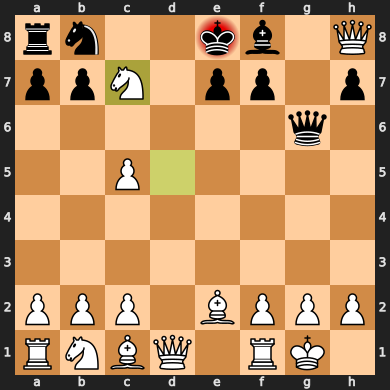

In [ ]:
play_ai_battle(white_type="mcts", black_type="dqn", mcts_simulations=50, max_moves=80)
